In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

# CHANGE THIS ONLY if your folder has a different name.
PROJECT_ROOT = Path('/content/drive/MyDrive/Atlantic_Ocean_Project')
OUTPUT_DIR = PROJECT_ROOT / 'inspection_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT_ROOT.exists(), f'Folder not found: {PROJECT_ROOT}'
print('Project folder:', PROJECT_ROOT)
print('Results folder:', OUTPUT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/Atlantic_Ocean_Project
Results folder: /content/drive/MyDrive/Atlantic_Ocean_Project/inspection_results


In [2]:
records = []
for p in PROJECT_ROOT.rglob('*'):
    if p.is_file() and OUTPUT_DIR not in p.parents:
        records.append({
            'relative_path': str(p.relative_to(PROJECT_ROOT)),
            'folder': str(p.parent.relative_to(PROJECT_ROOT)),
            'filename': p.name,
            'extension': p.suffix.lower() or '[none]',
            'size_bytes': p.stat().st_size,
            'size_mb': p.stat().st_size / 1024**2
        })

inventory = pd.DataFrame(records)
if inventory.empty:
    raise ValueError('No files found. Check PROJECT_ROOT.')

inventory.to_csv(OUTPUT_DIR / 'file_inventory.csv', index=False)
print(f'Total files: {len(inventory):,}')
print(f'Total size: {inventory.size_bytes.sum()/1024**3:.3f} GB')
display(inventory.groupby('extension').agg(files=('filename','count'), total_mb=('size_mb','sum')).sort_values('total_mb', ascending=False).round(3))
display(inventory.sort_values('size_mb', ascending=False).head(20))

Total files: 74
Total size: 0.029 GB


,files,total_mb
extension,,
.csv,19,19.177
.nc,18,8.815
.xml,18,1.236
.zip,1,0.461
.json,18,0.021


,relative_path,folder,filename,extension,size_bytes,size_mb
0,SB01_TOL_combined.csv,.,SB01_TOL_combined.csv,.csv,9666462,9.218657
2,SB01_TOL/sanctsound_sb01_18_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_18_tol_1h/data,SanctSound_SB01_18_TOL_1h.csv,.csv,753918,0.718992
70,SB01_TOL/sanctsound_sb01_01_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_01_tol_1h/data,SanctSound_SB01_01_TOL_1h.csv,.csv,717293,0.684064
3,SB01_TOL/sanctsound_sb01_18_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_18_tol_1h/data,SanctSound_SB01_18_TOL_1h.nc,.nc,659597,0.629041
71,SB01_TOL/sanctsound_sb01_01_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_01_tol_1h/data,SanctSound_SB01_01_TOL_1h.nc,.nc,624901,0.595952
43,SB01_TOL/sanctsound_sb01_08_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_08_tol_1h/data,SanctSound_SB01_08_TOL_1h.csv,.csv,624459,0.595531
14,SB01_TOL/sanctsound_sb01_15_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_15_tol_1h/data,SanctSound_SB01_15_TOL_1h.csv,.csv,623259,0.594386
39,SB01_TOL/sanctsound_sb01_09_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_09_tol_1h/data,SanctSound_SB01_09_TOL_1h.csv,.csv,615686,0.587164
26,SB01_TOL/sanctsound_sb01_12_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_12_tol_1h/data,SanctSound_SB01_12_TOL_1h.csv,.csv,614982,0.586493
23,SB01_TOL/sanctsound_sb01_13_tol_1h/data/SanctS...,SB01_TOL/sanctsound_sb01_13_tol_1h/data,SanctSound_SB01_13_TOL_1h.csv,.csv,605367,0.577323


In [3]:
def read_csv_safely(path, nrows=None):
    for encoding in ('utf-8', 'utf-8-sig', 'latin-1'):
        try:
            return pd.read_csv(path, nrows=nrows, low_memory=False, encoding=encoding)
        except UnicodeDecodeError:
            pass
    return pd.read_csv(path, nrows=nrows, low_memory=False)

def find_time_column(df):
    preferred = ['yyyy-mm-ddTHH:MM:SSZ', 'time', 'timestamp', 'datetime', 'date',
                 'start_time', 'end_time', 'DateTime', 'DATE_TIME']
    for c in preferred:
        if c in df.columns:
            return c
    for c in df.columns:
        name = str(c).lower()
        if any(x in name for x in ('time', 'date')) and 'frequency' not in name:
            return c
    # Last resort: test object/string columns on a sample.
    for c in df.select_dtypes(include=['object', 'string']).columns:
        parsed = pd.to_datetime(df[c].head(100), errors='coerce', utc=True)
        if parsed.notna().mean() >= 0.8:
            return c
    return None

csv_files = [Path(x) for x in inventory.loc[inventory.extension == '.csv', 'relative_path'].map(lambda x: PROJECT_ROOT / x)]
csv_summaries, column_records, csv_errors = [], [], []

for path in csv_files:
    try:
        df = read_csv_safely(path)
        df.columns = [str(c).strip() for c in df.columns]
        time_col = find_time_column(df)
        parsed = pd.to_datetime(df[time_col], errors='coerce', utc=True) if time_col else pd.Series(dtype='datetime64[ns, UTC]')
        numeric = df.select_dtypes(include=np.number)
        csv_summaries.append({
            'file': str(path.relative_to(PROJECT_ROOT)),
            'rows': len(df),
            'columns': len(df.columns),
            'time_column': time_col,
            'valid_timestamps': int(parsed.notna().sum()),
            'start_utc': parsed.min(),
            'end_utc': parsed.max(),
            'duplicate_rows': int(df.duplicated().sum()),
            'missing_cells': int(df.isna().sum().sum()),
            'missing_percent': 100 * df.isna().sum().sum() / max(df.size, 1),
            'numeric_columns': len(numeric.columns),
            'memory_mb': df.memory_usage(deep=True).sum()/1024**2
        })
        for c in df.columns:
            column_records.append({
                'file': str(path.relative_to(PROJECT_ROOT)),
                'column': c,
                'dtype': str(df[c].dtype),
                'non_null': int(df[c].notna().sum()),
                'missing': int(df[c].isna().sum()),
                'unique_values': int(df[c].nunique(dropna=True))
            })
    except Exception as e:
        csv_errors.append({'file': str(path.relative_to(PROJECT_ROOT)), 'error': repr(e)})

csv_summary = pd.DataFrame(csv_summaries)
column_summary = pd.DataFrame(column_records)
csv_summary.to_csv(OUTPUT_DIR / 'csv_dataset_summary.csv', index=False)
column_summary.to_csv(OUTPUT_DIR / 'csv_column_summary.csv', index=False)
pd.DataFrame(csv_errors).to_csv(OUTPUT_DIR / 'csv_read_errors.csv', index=False)
print(f'CSV files inspected: {len(csv_summary):,}; errors: {len(csv_errors):,}')
display(csv_summary)

CSV files inspected: 19; errors: 0


,file,rows,columns,time_column,valid_timestamps,start_utc,end_utc,duplicate_rows,missing_cells,missing_percent,numeric_columns,memory_mb
0,SB01_TOL_combined.csv,26873,35,yyyy-mm-ddTHH:MM:SSZ,26873,2018-11-12 19:00:00+00:00,2021-12-15 15:00:00+00:00,0,0,0.0,33,10.071965
1,SB01_TOL/sanctsound_sb01_18_tol_1h/data/SanctS...,1942,34,yyyy-mm-ddTHH:MM:SSZ,1942,2021-09-25 18:00:00+00:00,2021-12-15 15:00:00+00:00,0,0,0.0,33,0.624262
2,SB01_TOL/sanctsound_sb01_17_tol_1h/data/SanctS...,1437,34,yyyy-mm-ddTHH:MM:SSZ,1437,2021-07-27 18:00:00+00:00,2021-09-25 14:00:00+00:00,0,0,0.0,33,0.461961
3,SB01_TOL/sanctsound_sb01_16_tol_1h/data/SanctS...,1465,34,yyyy-mm-ddTHH:MM:SSZ,1465,2021-05-27 14:00:00+00:00,2021-07-27 14:00:00+00:00,0,0,0.0,33,0.470960
4,SB01_TOL/sanctsound_sb01_15_tol_1h/data/SanctS...,1601,34,yyyy-mm-ddTHH:MM:SSZ,1601,2021-03-21 19:00:00+00:00,2021-05-27 11:00:00+00:00,0,0,0.0,33,0.514668
5,SB01_TOL/sanctsound_sb01_14_tol_1h/data/SanctS...,1292,34,yyyy-mm-ddTHH:MM:SSZ,1292,2021-01-26 20:00:00+00:00,2021-03-21 15:00:00+00:00,0,0,0.0,33,0.415359
6,SB01_TOL/sanctsound_sb01_13_tol_1h/data/SanctS...,1559,34,yyyy-mm-ddTHH:MM:SSZ,1559,2020-11-22 19:00:00+00:00,2021-01-26 17:00:00+00:00,0,0,0.0,33,0.501170
7,SB01_TOL/sanctsound_sb01_12_tol_1h/data/SanctS...,1584,34,yyyy-mm-ddTHH:MM:SSZ,1584,2020-09-17 18:00:00+00:00,2020-11-22 17:00:00+00:00,0,0,0.0,33,0.509205
8,SB01_TOL/sanctsound_sb01_11_tol_1h/data/SanctS...,813,34,yyyy-mm-ddTHH:MM:SSZ,813,2020-08-14 18:00:00+00:00,2020-09-17 14:00:00+00:00,0,0,0.0,33,0.261415
9,SB01_TOL/sanctsound_sb01_10_tol_1h/data/SanctS...,1509,34,yyyy-mm-ddTHH:MM:SSZ,1509,2020-06-12 19:00:00+00:00,2020-08-14 15:00:00+00:00,0,0,0.0,33,0.485101


In [4]:
tol_files = [p for p in csv_files if 'tol_1h' in p.name.lower()]
tol_frames, deployment_rows = [], []

for path in sorted(tol_files):
    df = read_csv_safely(path)
    df.columns = [str(c).strip() for c in df.columns]
    time_col = find_time_column(df)
    if time_col is None:
        continue
    df['timestamp_utc'] = pd.to_datetime(df[time_col], errors='coerce', utc=True)
    df = df.dropna(subset=['timestamp_utc']).copy()
    band_cols = [c for c in df.columns if re.fullmatch(r'TOL_\d+(?:\.\d+)?', c, flags=re.I)]
    deployment = re.search(r'SB01_(\d+)', path.name, flags=re.I)
    deployment = int(deployment.group(1)) if deployment else np.nan
    deployment_rows.append({
        'deployment': deployment, 'file': path.name, 'rows': len(df),
        'start_utc': df.timestamp_utc.min(), 'end_utc': df.timestamp_utc.max(),
        'frequency_bands': len(band_cols),
        'duplicate_timestamps': int(df.timestamp_utc.duplicated().sum()),
        'missing_acoustic_cells': int(df[band_cols].isna().sum().sum())
    })
    tol_frames.append(df[['timestamp_utc'] + band_cols].assign(deployment=deployment))

deployments = pd.DataFrame(deployment_rows).sort_values('deployment')
deployments.to_csv(OUTPUT_DIR / 'tol_deployment_summary.csv', index=False)
display(deployments)

if not tol_frames:
    raise ValueError('No TOL_1h CSV files were found.')

tol = pd.concat(tol_frames, ignore_index=True).sort_values('timestamp_utc')
tol = tol.drop_duplicates(subset='timestamp_utc', keep='first')
band_cols = [c for c in tol.columns if re.fullmatch(r'TOL_\d+(?:\.\d+)?', c, flags=re.I)]
tol['gap_hours'] = tol.timestamp_utc.diff().dt.total_seconds()/3600
gaps = tol.loc[tol.gap_hours > 1, ['timestamp_utc', 'gap_hours']].copy()
gaps['previous_timestamp_utc'] = gaps.timestamp_utc - pd.to_timedelta(gaps.gap_hours, unit='h')
gaps['missing_hours_between'] = gaps.gap_hours - 1
gaps.to_csv(OUTPUT_DIR / 'tol_time_gaps.csv', index=False)

start, end = tol.timestamp_utc.min(), tol.timestamp_utc.max()
expected_hours = int((end-start).total_seconds()/3600) + 1
overall = pd.DataFrame([{
    'start_utc': start, 'end_utc': end,
    'calendar_days': (end-start).total_seconds()/86400,
    'calendar_years': (end-start).total_seconds()/(365.25*86400),
    'unique_hourly_observations': len(tol),
    'expected_hours_if_continuous': expected_hours,
    'missing_hours': expected_hours-len(tol),
    'coverage_percent': 100*len(tol)/expected_hours,
    'deployments': len(deployments),
    'frequency_bands': len(band_cols),
    'sound_level_values': len(tol)*len(band_cols),
    'missing_sound_level_values': int(tol[band_cols].isna().sum().sum())
}])
overall.to_csv(OUTPUT_DIR / 'tol_overall_summary.csv', index=False)
display(overall.T.rename(columns={0:'value'}))
print('Frequency columns:', band_cols)
print('Number of gaps longer than one hour:', len(gaps))
display(gaps.sort_values('missing_hours_between', ascending=False).head(20))

,deployment,file,rows,start_utc,end_utc,frequency_bands,duplicate_timestamps,missing_acoustic_cells
0,1,SanctSound_SB01_01_TOL_1h.csv,1846,2018-11-12 19:00:00+00:00,2019-01-28 16:00:00+00:00,33,0,0
1,2,SanctSound_SB01_02_TOL_1h.csv,1531,2019-01-28 18:00:00+00:00,2019-04-02 12:00:00+00:00,33,0,0
2,3,SanctSound_SB01_03_TOL_1h.csv,1260,2019-04-10 04:00:00+00:00,2019-06-01 15:00:00+00:00,33,0,0
3,4,SanctSound_SB01_04_TOL_1h.csv,1487,2019-06-01 18:00:00+00:00,2019-08-02 16:00:00+00:00,33,0,0
4,5,SanctSound_SB01_05_TOL_1h.csv,1532,2019-08-02 19:00:00+00:00,2019-10-05 14:00:00+00:00,33,0,0
5,6,SanctSound_SB01_06_TOL_1h.csv,1486,2019-10-05 16:00:00+00:00,2019-12-06 13:00:00+00:00,33,0,0
6,7,SanctSound_SB01_07_TOL_1h.csv,1340,2019-12-06 16:00:00+00:00,2020-01-31 11:00:00+00:00,33,0,0
7,8,SanctSound_SB01_08_TOL_1h.csv,1608,2020-01-31 15:00:00+00:00,2020-04-07 18:00:00+00:00,33,0,0
8,9,SanctSound_SB01_09_TOL_1h.csv,1581,2020-04-07 21:00:00+00:00,2020-06-12 17:00:00+00:00,33,0,0
9,10,SanctSound_SB01_10_TOL_1h.csv,1509,2020-06-12 19:00:00+00:00,2020-08-14 15:00:00+00:00,33,0,0


,value
start_utc,2018-11-12 19:00:00+00:00
end_utc,2021-12-15 15:00:00+00:00
calendar_days,1128.833333
calendar_years,3.090577
unique_hourly_observations,26873
expected_hours_if_continuous,27093
missing_hours,220
coverage_percent,99.187982
deployments,18
frequency_bands,33


Frequency columns: ['TOL_13', 'TOL_16', 'TOL_20', 'TOL_25', 'TOL_31.5', 'TOL_40', 'TOL_50', 'TOL_63', 'TOL_80', 'TOL_100', 'TOL_125', 'TOL_160', 'TOL_200', 'TOL_250', 'TOL_315', 'TOL_400', 'TOL_500', 'TOL_630', 'TOL_800', 'TOL_1000', 'TOL_1250', 'TOL_1600', 'TOL_2000', 'TOL_2500', 'TOL_3150', 'TOL_4000', 'TOL_5000', 'TOL_6300', 'TOL_8000', 'TOL_10000', 'TOL_12500', 'TOL_16000', 'TOL_20000']
Number of gaps longer than one hour: 19


,timestamp_utc,gap_hours,previous_timestamp_utc,missing_hours_between
3377,2019-04-10 04:00:00+00:00,184.0,2019-04-02 12:00:00+00:00,183.0
11574,2020-03-17 06:00:00+00:00,4.0,2020-03-17 02:00:00+00:00,3.0
10482,2020-01-31 15:00:00+00:00,4.0,2020-01-31 11:00:00+00:00,3.0
20428,2021-03-21 19:00:00+00:00,4.0,2021-03-21 15:00:00+00:00,3.0
23494,2021-07-27 18:00:00+00:00,4.0,2021-07-27 14:00:00+00:00,3.0
24931,2021-09-25 18:00:00+00:00,4.0,2021-09-25 14:00:00+00:00,3.0
15993,2020-09-17 18:00:00+00:00,4.0,2020-09-17 14:00:00+00:00,3.0
15180,2020-08-14 18:00:00+00:00,3.0,2020-08-14 15:00:00+00:00,2.0
4637,2019-06-01 18:00:00+00:00,3.0,2019-06-01 15:00:00+00:00,2.0
9142,2019-12-06 16:00:00+00:00,3.0,2019-12-06 13:00:00+00:00,2.0


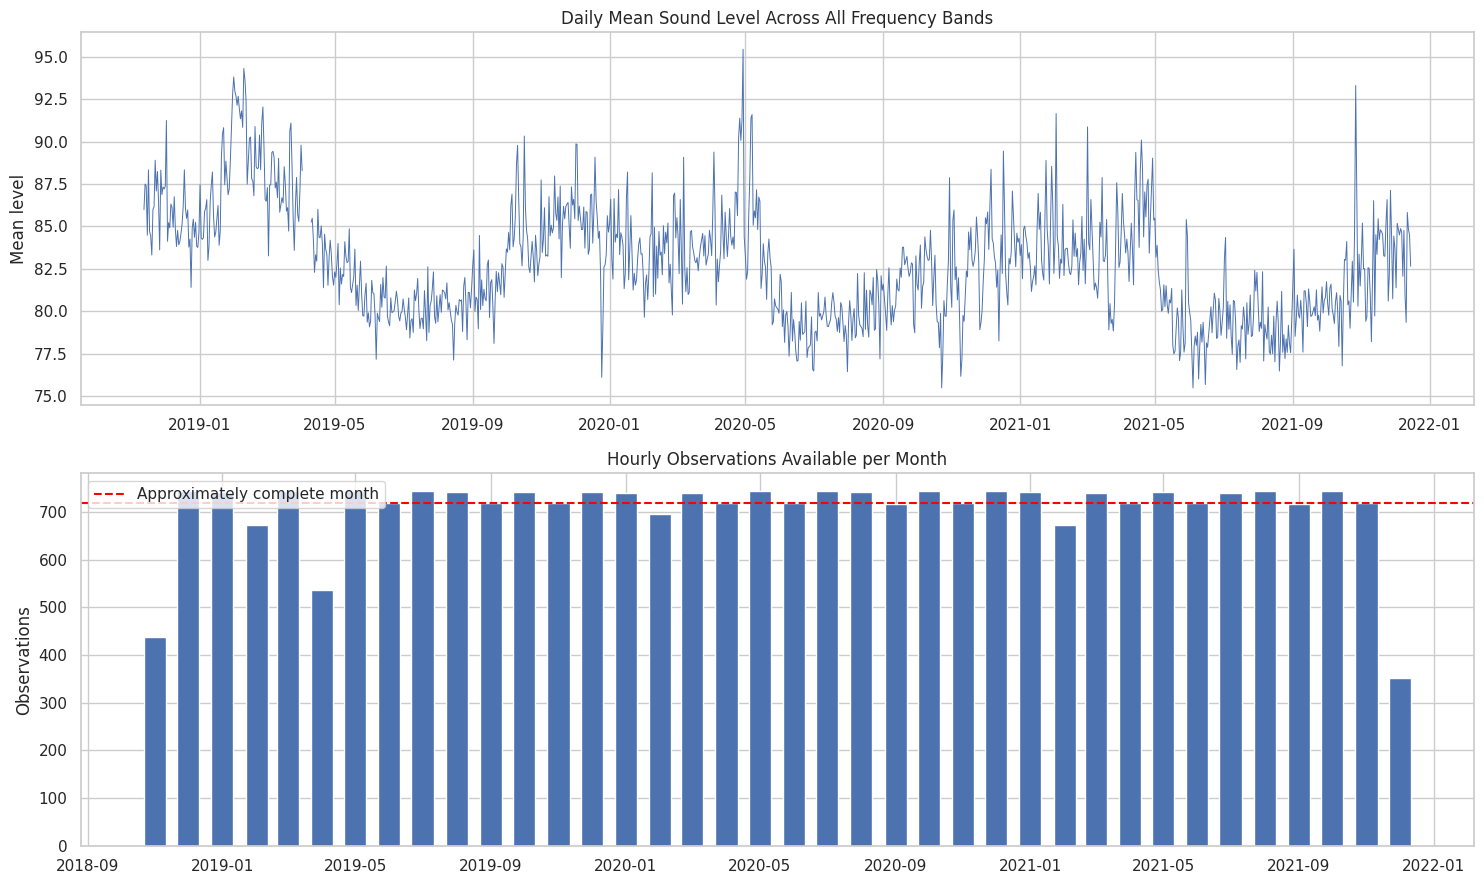

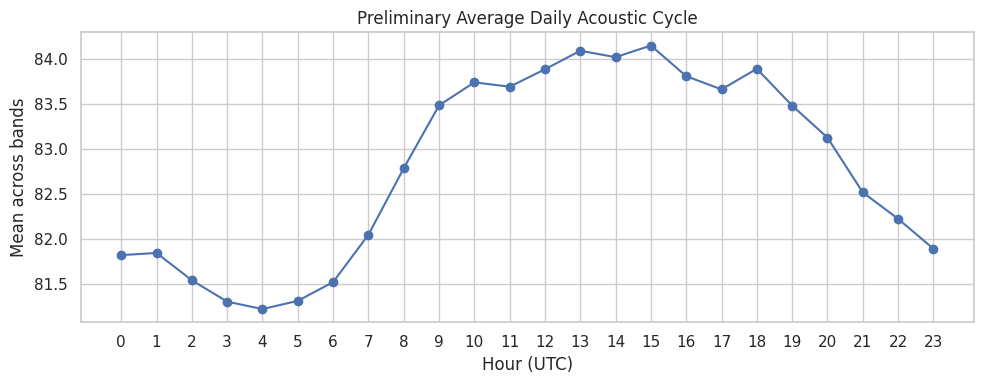

In [5]:
plot_df = tol.set_index('timestamp_utc')[band_cols].apply(pd.to_numeric, errors='coerce')
daily = plot_df.resample('1D').mean()

fig, axes = plt.subplots(2, 1, figsize=(15,9))
axes[0].plot(daily.index, daily.mean(axis=1), linewidth=.7)
axes[0].set(title='Daily Mean Sound Level Across All Frequency Bands', ylabel='Mean level')

monthly_counts = plot_df.resample('MS').size()
axes[1].bar(monthly_counts.index, monthly_counts.values, width=20)
axes[1].axhline(24*30, color='red', linestyle='--', label='Approximately complete month')
axes[1].set(title='Hourly Observations Available per Month', ylabel='Observations')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'temporal_coverage.png', dpi=200)
plt.show()

# Average 24-hour cycle in UTC. Local solar interpretation can be added later.
hourly_cycle = plot_df.assign(hour=plot_df.index.hour).groupby('hour').mean().mean(axis=1)
plt.figure(figsize=(10,4))
plt.plot(hourly_cycle.index, hourly_cycle.values, marker='o')
plt.xticks(range(24))
plt.xlabel('Hour (UTC)')
plt.ylabel('Mean across bands')
plt.title('Preliminary Average Daily Acoustic Cycle')
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'preliminary_daily_cycle.png', dpi=200)
plt.show()

In [6]:
o = overall.iloc[0]
report_text = f'''ATLANTIC OCEAN DATA INSPECTION RESULTS
Project folder: {PROJECT_ROOT}
Total files: {len(inventory):,}
Total stored size: {inventory.size_bytes.sum()/1024**3:.3f} GB
CSV files inspected: {len(csv_summary):,}

HOURLY ACOUSTIC DATA
Start (UTC): {o.start_utc}
End (UTC): {o.end_utc}
Calendar span: {o.calendar_years:.3f} years
Unique hourly observations: {int(o.unique_hourly_observations):,}
Expected hours if continuous: {int(o.expected_hours_if_continuous):,}
Missing hours: {int(o.missing_hours):,}
Coverage: {o.coverage_percent:.2f}%
Deployments: {int(o.deployments)}
Frequency bands: {int(o.frequency_bands)}
Sound-level values: {int(o.sound_level_values):,}
Missing sound-level values: {int(o.missing_sound_level_values):,}
Gaps longer than one hour: {len(gaps):,}
CSV read errors: {len(csv_errors):,}

OUTPUT FILES
{chr(10).join(sorted(p.name for p in OUTPUT_DIR.iterdir()))}
'''
print(report_text)
(OUTPUT_DIR/'COPY_THIS_SUMMARY.txt').write_text(report_text)

# Zip all small summaries and plots for easy sharing.
import shutil
zip_path = shutil.make_archive(str(PROJECT_ROOT/'Atlantic_Data_Inspection_Results'), 'zip', OUTPUT_DIR)
print('Saved ZIP:', zip_path)

ATLANTIC OCEAN DATA INSPECTION RESULTS
Project folder: /content/drive/MyDrive/Atlantic_Ocean_Project
Total files: 74
Total stored size: 0.029 GB
CSV files inspected: 19

HOURLY ACOUSTIC DATA
Start (UTC): 2018-11-12 19:00:00+00:00
End (UTC): 2021-12-15 15:00:00+00:00
Calendar span: 3.091 years
Unique hourly observations: 26,873
Expected hours if continuous: 27,093
Missing hours: 220
Coverage: 99.19%
Deployments: 18
Frequency bands: 33
Sound-level values: 886,809
Missing sound-level values: 0
Gaps longer than one hour: 19
CSV read errors: 0

OUTPUT FILES
COPY_THIS_SUMMARY.txt
csv_column_summary.csv
csv_dataset_summary.csv
csv_read_errors.csv
file_inventory.csv
preliminary_daily_cycle.png
temporal_coverage.png
tol_deployment_summary.csv
tol_overall_summary.csv
tol_time_gaps.csv

Saved ZIP: /content/drive/MyDrive/Atlantic_Ocean_Project/Atlantic_Data_Inspection_Results.zip


ALL


In [7]:
from pathlib import Path
import pandas as pd
import os

TEAM_ROOT = Path("/content/drive/MyDrive/Data Mining Project")

files = [
    TEAM_ROOT / "all.csv",
    TEAM_ROOT / "ships_hourly.csv",
    TEAM_ROOT / "weather_hourly.csv"
]

def detect_time_column(df):
    preferred = [
        "time", "timestamp", "datetime", "date",
        "start_time", "end_time",
        "yyyy-mm-ddTHH:MM:SSZ"
    ]

    for candidate in preferred:
        for column in df.columns:
            if column.lower() == candidate.lower():
                return column

    for column in df.columns:
        name = column.lower()
        if "time" in name or "date" in name:
            return column

    return None

summaries = []

for file in files:
    print("\n" + "=" * 80)
    print("FILE:", file.name)

    if not file.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(file, low_memory=False)
    df.columns = df.columns.astype(str).str.strip()

    time_col = detect_time_column(df)

    if time_col:
        timestamps = pd.to_datetime(
            df[time_col],
            errors="coerce",
            utc=True
        )
        start = timestamps.min()
        end = timestamps.max()
        valid_dates = timestamps.notna().sum()
        duplicate_times = timestamps.duplicated().sum()
    else:
        start = end = None
        valid_dates = duplicate_times = 0

    summary = {
        "file": file.name,
        "size_mb": os.path.getsize(file) / 1024**2,
        "rows": len(df),
        "columns": len(df.columns),
        "time_column": time_col,
        "start": start,
        "end": end,
        "valid_timestamps": valid_dates,
        "duplicate_rows": df.duplicated().sum(),
        "duplicate_timestamps": duplicate_times,
        "missing_cells": df.isna().sum().sum(),
        "missing_percent": 100 * df.isna().sum().sum() / df.size
    }

    summaries.append(summary)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Time column:", time_col)
    print("Date range:", start, "to", end)
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing cells:", df.isna().sum().sum())

    print("\nFirst five rows:")
    display(df.head())

    print("\nMissing values by column:")
    missing = pd.DataFrame({
        "missing": df.isna().sum(),
        "missing_percent": df.isna().mean() * 100,
        "unique_values": df.nunique(dropna=True),
        "data_type": df.dtypes.astype(str)
    })
    display(missing.sort_values("missing", ascending=False))

team_summary = pd.DataFrame(summaries)
display(team_summary)

team_summary.to_csv(
    TEAM_ROOT / "team_dataset_summary.csv",
    index=False
)


FILE: all.csv
Shape: (886809, 5)
Columns: ['source_file', 'deployment', 'time', 'frequency', 'sound_pressure_levels']
Time column: time
Date range: 2018-11-12 19:00:00+00:00 to 2021-12-15 15:00:00+00:00
Duplicate rows: 0
Missing cells: 0

First five rows:


,source_file,deployment,time,frequency,sound_pressure_levels
0,noaaSanctSound_SB01_01_TOL_1h.csv,SB01_01,2018-11-12T19:00:00Z,13.0,65.362056
1,noaaSanctSound_SB01_01_TOL_1h.csv,SB01_01,2018-11-12T19:00:00Z,16.0,65.213209
2,noaaSanctSound_SB01_01_TOL_1h.csv,SB01_01,2018-11-12T19:00:00Z,20.0,70.004406
3,noaaSanctSound_SB01_01_TOL_1h.csv,SB01_01,2018-11-12T19:00:00Z,25.0,75.742012
4,noaaSanctSound_SB01_01_TOL_1h.csv,SB01_01,2018-11-12T19:00:00Z,31.5,83.279053



Missing values by column:


,missing,missing_percent,unique_values,data_type
source_file,0,0.0,18,object
deployment,0,0.0,18,object
time,0,0.0,26873,object
frequency,0,0.0,33,float64
sound_pressure_levels,0,0.0,873312,float64



FILE: ships_hourly.csv
Shape: (27093, 4)
Columns: ['hour_utc', 'deployment', 'ship_minutes', 'ship_present']
Time column: None
Date range: None to None
Duplicate rows: 0
Missing cells: 627

First five rows:


...


FILE: weather_hourly.csv
Shape: (27093, 11)
Columns: ['hour_utc', 'WDIR', 'WSPD', 'GST', 'PRES', 'ATMP', 'WTMP', 'DEWP', 'WVHT_44098', 'DPD_44098', 'APD_44098']
Time column: None
Date range: None to None
Duplicate rows: 0
Missing cells: 18650

First five rows:


,hour_utc,WDIR,WSPD,GST,PRES,ATMP,WTMP,DEWP,WVHT_44098,DPD_44098,APD_44098
0,2018-11-12 19:00:00+00:00,178.0,4.4,6.0,1027.9,8.5,11.5,-2.7,NaN,NaN,NaN
1,2018-11-12 20:00:00+00:00,181.0,6.5,7.4,1028.5,8.7,11.4,-1.7,NaN,NaN,NaN
2,2018-11-12 21:00:00+00:00,187.0,6.7,7.7,1028.8,8.5,11.4,-1.1,NaN,NaN,NaN
3,2018-11-12 22:00:00+00:00,181.0,6.6,8.4,1029.3,8.5,11.3,0.5,NaN,NaN,NaN
4,2018-11-12 23:00:00+00:00,176.0,6.7,7.8,1028.9,8.4,11.3,1.7,NaN,NaN,NaN



Missing values by column:


,missing,missing_percent,unique_values,data_type
DEWP,4908,18.115380,2164,float64
ATMP,4684,17.288599,1908,float64
WVHT_44098,1937,7.149448,1124,float64
APD_44098,1937,7.149448,1713,float64
DPD_44098,1937,7.149448,525,float64
WDIR,734,2.709187,2109,float64
WSPD,734,2.709187,1158,float64
GST,734,2.709187,1405,float64
WTMP,523,1.930388,1433,float64
PRES,522,1.926697,2499,float64


,file,size_mb,rows,columns,time_column,start,end,valid_timestamps,duplicate_rows,duplicate_timestamps,missing_cells,missing_percent
0,all.csv,66.958475,886809,5,time,2018-11-12 19:00:00+00:00,2021-12-15 15:00:00+00:00,886809,0,859936,0,0.000000
1,ships_hourly.csv,1.154757,27093,4,None,NaT,NaT,0,0,0,627,0.578563
2,weather_hourly.csv,2.667222,27093,11,None,NaT,NaT,0,0,0,18650,6.257906


In [8]:
import pandas as pd
from pathlib import Path

TEAM_ROOT = Path("/content/drive/MyDrive/Data Mining Project")

sound = pd.read_csv(TEAM_ROOT / "all.csv", low_memory=False)
ships = pd.read_csv(TEAM_ROOT / "ships_hourly.csv")
weather = pd.read_csv(TEAM_ROOT / "weather_hourly.csv")

sound["time"] = pd.to_datetime(sound["time"], utc=True)
ships["hour_utc"] = pd.to_datetime(ships["hour_utc"], utc=True)
weather["hour_utc"] = pd.to_datetime(weather["hour_utc"], utc=True)

print("SOUND")
print("Range:", sound.time.min(), "to", sound.time.max())
print("Unique hours:", sound.time.nunique())
print("Frequencies:", sound.frequency.nunique())
print("Deployments:", sound.deployment.nunique())

print("\nSHIPS")
print("Range:", ships.hour_utc.min(), "to", ships.hour_utc.max())
print("Unique hours:", ships.hour_utc.nunique())
print("Hours with vessel data:", ships.ship_present.notna().sum())
print("Hours with ships present:", int(ships.ship_present.fillna(0).sum()))

print("\nWEATHER")
print("Range:", weather.hour_utc.min(), "to", weather.hour_utc.max())
print("Unique hours:", weather.hour_utc.nunique())

# Convert sound data from long form to a time-series matrix
sound_matrix = sound.pivot(
    index="time",
    columns="frequency",
    values="sound_pressure_levels"
)

sound_matrix.columns = [
    f"sound_{frequency:g}Hz"
    for frequency in sound_matrix.columns
]

# Combine acoustic, vessel, and weather measurements by hour
combined = (
    sound_matrix
    .merge(
        ships.set_index("hour_utc"),
        left_index=True,
        right_index=True,
        how="outer"
    )
    .merge(
        weather.set_index("hour_utc"),
        left_index=True,
        right_index=True,
        how="outer"
    )
)

print("\nCOMBINED MATRIX")
print("Shape:", combined.shape)
print("Date range:", combined.index.min(), "to", combined.index.max())
print("Hours with acoustic data:", sound_matrix.shape[0])
print("Hours with complete sound and ship data:",
      combined[sound_matrix.columns].notna().all(axis=1)
      & combined["ship_present"].notna())
print("Columns:", combined.columns.tolist())

combined.to_csv(TEAM_ROOT / "combined_hourly_data.csv")

SOUND
Range: 2018-11-12 19:00:00+00:00 to 2021-12-15 15:00:00+00:00
Unique hours: 26873
Frequencies: 33
Deployments: 18

SHIPS
Range: 2018-11-12 19:00:00+00:00 to 2021-12-15 15:00:00+00:00
Unique hours: 27093
Hours with vessel data: 26884
Hours with ships present: 22837

WEATHER
Range: 2018-11-12 19:00:00+00:00 to 2021-12-15 15:00:00+00:00
Unique hours: 27093

COMBINED MATRIX
Shape: (27093, 46)
Date range: 2018-11-12 19:00:00+00:00 to 2021-12-15 15:00:00+00:00
Hours with acoustic data: 26873
Hours with complete sound and ship data: 2018-11-12 19:00:00+00:00    True
2018-11-12 20:00:00+00:00    True
2018-11-12 21:00:00+00:00    True
2018-11-12 22:00:00+00:00    True
2018-11-12 23:00:00+00:00    True
                             ... 
2021-12-15 11:00:00+00:00    True
2021-12-15 12:00:00+00:00    True
2021-12-15 13:00:00+00:00    True
2021-12-15 14:00:00+00:00    True
2021-12-15 15:00:00+00:00    True
Length: 27093, dtype: bool
Columns: ['sound_13Hz', 'sound_16Hz', 'sound_20Hz', 'sound_25

In [9]:
complete_sound_ship = (
    combined[sound_matrix.columns].notna().all(axis=1)
    & combined["ship_present"].notna()
).sum()

print("Hours with complete sound and ship data:", complete_sound_ship)

Hours with complete sound and ship data: 26867


In [12]:
from pathlib import Path
import pandas as pd
import numpy as np
import os

PROJECT_ROOT = Path("/content/drive/MyDrive/Data Mining Project")
ANIMAL_ROOT = PROJECT_ROOT / "Animal sounds"
ANIMAL_FILE = ANIMAL_ROOT / "animals.csv"
RAW_ROOT = ANIMAL_ROOT / "raw"

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def read_csv_safely(path, nrows=None):
    for encoding in ["utf-8", "utf-8-sig", "latin-1"]:
        try:
            return pd.read_csv(
                path,
                nrows=nrows,
                encoding=encoding,
                low_memory=False
            )
        except UnicodeDecodeError:
            continue

    return pd.read_csv(path, nrows=nrows, low_memory=False)


def find_time_column(df):
    preferred = [
        "time", "hour_utc", "date", "datetime", "timestamp",
        "start_time", "end_time", "day", "date_time",
        "yyyy-mm-ddTHH:MM:SSZ"
    ]

    for preferred_name in preferred:
        for column in df.columns:
            if column.lower() == preferred_name.lower():
                return column

    for column in df.columns:
        name = column.lower()

        if "time" in name or "date" in name or "day" in name:
            parsed = pd.to_datetime(
                df[column].head(500),
                errors="coerce",
                utc=True
            )

            if parsed.notna().mean() >= 0.5:
                return column

    return None


def estimate_resolution(timestamps):
    unique_times = timestamps.dropna().drop_duplicates().sort_values()

    if len(unique_times) < 2:
        return None

    differences = unique_times.diff().dropna()
    return differences.median()


# ------------------------------------------------------------
# Load combined animal data
# ------------------------------------------------------------

assert ANIMAL_FILE.exists(), f"File not found: {ANIMAL_FILE}"

animals = read_csv_safely(ANIMAL_FILE)
animals.columns = animals.columns.astype(str).str.strip()

print("=" * 80)
print("COMBINED ANIMAL DATA")
print("=" * 80)

print("File:", ANIMAL_FILE)
print("File size:", round(os.path.getsize(ANIMAL_FILE) / 1024**2, 3), "MB")
print("Shape:", animals.shape)
print("Rows:", f"{len(animals):,}")
print("Columns:", len(animals.columns))
print("Column names:", animals.columns.tolist())
print("Duplicate rows:", f"{animals.duplicated().sum():,}")
print("Missing cells:", f"{animals.isna().sum().sum():,}")
print(
    "Missing percentage:",
    round(100 * animals.isna().sum().sum() / animals.size, 3),
    "%"
)

print("\nFIRST FIVE ROWS")
display(animals.head())

# ------------------------------------------------------------
# Column-level inspection
# ------------------------------------------------------------

column_summary = pd.DataFrame({
    "data_type": animals.dtypes.astype(str),
    "non_missing": animals.notna().sum(),
    "missing": animals.isna().sum(),
    "missing_percent": animals.isna().mean() * 100,
    "unique_values": animals.nunique(dropna=True)
})

print("\nCOLUMN SUMMARY")
display(column_summary.round(3))

# ------------------------------------------------------------
# Find and inspect timestamp
# ------------------------------------------------------------

time_col = find_time_column(animals)

print("\nTIME INFORMATION")
print("Detected time column:", time_col)

if time_col:
    animals["parsed_time"] = pd.to_datetime(
        animals[time_col],
        errors="coerce",
        utc=True
    )

    valid_times = animals["parsed_time"].dropna()
    resolution = estimate_resolution(valid_times)

    print("Valid timestamps:", f"{valid_times.notna().sum():,}")
    print("Unique timestamps:", f"{valid_times.nunique():,}")
    print("Start:", valid_times.min())
    print("End:", valid_times.max())
    print("Estimated time resolution:", resolution)
else:
    print("No timestamp column was detected.")

# ------------------------------------------------------------
# Find species, animal, detection and presence columns
# ------------------------------------------------------------

species_columns = [
    column for column in animals.columns
    if any(word in column.lower() for word in [
        "species", "animal", "common_name", "scientific_name",
        "whale", "dolphin", "fish"
    ])
]

detection_columns = [
    column for column in animals.columns
    if any(word in column.lower() for word in [
        "presence", "present", "detection", "detected",
        "calls", "minutes", "hours", "count"
    ])
]

deployment_columns = [
    column for column in animals.columns
    if any(word in column.lower() for word in [
        "deployment", "site", "station", "source_file"
    ])
]

print("\nPOSSIBLE SPECIES COLUMNS:", species_columns)
print("POSSIBLE DETECTION COLUMNS:", detection_columns)
print("POSSIBLE DEPLOYMENT COLUMNS:", deployment_columns)

for column in species_columns + detection_columns + deployment_columns:
    print("\n" + "-" * 60)
    print("COLUMN:", column)
    print(animals[column].value_counts(dropna=False).head(40))

# Show low-cardinality categorical columns that may encode species
print("\nOTHER LOW-CARDINALITY COLUMNS")

for column in animals.columns:
    unique_count = animals[column].nunique(dropna=True)

    if (
        column != time_col
        and column != "parsed_time"
        and 2 <= unique_count <= 50
    ):
        print(f"\n{column} ({unique_count} unique values)")
        print(animals[column].value_counts(dropna=False).head(50))

# ------------------------------------------------------------
# Inventory and inspect every raw animal CSV
# ------------------------------------------------------------

raw_files = sorted(RAW_ROOT.rglob("*.csv")) if RAW_ROOT.exists() else []

print("\n" + "=" * 80)
print("RAW ANIMAL FILES")
print("=" * 80)
print("Number of raw CSV files:", len(raw_files))

raw_summaries = []

for path in raw_files:
    try:
        df = read_csv_safely(path)
        df.columns = df.columns.astype(str).str.strip()

        raw_time_col = find_time_column(df)

        if raw_time_col:
            raw_times = pd.to_datetime(
                df[raw_time_col],
                errors="coerce",
                utc=True
            )
        else:
            raw_times = pd.Series(dtype="datetime64[ns, UTC]")

        raw_summaries.append({
            "file": str(path.relative_to(ANIMAL_ROOT)),
            "size_mb": os.path.getsize(path) / 1024**2,
            "rows": len(df),
            "columns": len(df.columns),
            "column_names": " | ".join(df.columns),
            "time_column": raw_time_col,
            "start": raw_times.min(),
            "end": raw_times.max(),
            "unique_times": raw_times.nunique(),
            "duplicate_rows": df.duplicated().sum(),
            "missing_cells": df.isna().sum().sum(),
            "missing_percent":
                100 * df.isna().sum().sum() / max(df.size, 1)
        })

    except Exception as error:
        raw_summaries.append({
            "file": str(path.relative_to(ANIMAL_ROOT)),
            "error": repr(error)
        })

raw_summary = pd.DataFrame(raw_summaries)

if len(raw_summary):
    display(raw_summary)
else:
    print("No raw CSV files found.")

# ------------------------------------------------------------
# Calculate overlap with the project timeline
# ------------------------------------------------------------

PROJECT_START = pd.Timestamp("2018-11-12 19:00:00", tz="UTC")
PROJECT_END = pd.Timestamp("2021-12-15 15:00:00", tz="UTC")

print("\n" + "=" * 80)
print("OVERLAP WITH ACOUSTIC PROJECT PERIOD")
print("=" * 80)

if time_col:
    overlap = animals[
        animals["parsed_time"].between(PROJECT_START, PROJECT_END)
    ]

    print("Project period:", PROJECT_START, "to", PROJECT_END)
    print("Animal rows inside project period:", f"{len(overlap):,}")
    print(
        "Unique animal timestamps inside project period:",
        f"{overlap['parsed_time'].nunique():,}"
    )
    print(
        "Percentage of animal rows inside project period:",
        round(100 * len(overlap) / len(animals), 2),
        "%"
    )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

column_summary.to_csv(
    ANIMAL_ROOT / "animal_column_summary.csv"
)

raw_summary.to_csv(
    ANIMAL_ROOT / "animal_raw_file_summary.csv",
    index=False
)

print("\nSaved:")
print(ANIMAL_ROOT / "animal_column_summary.csv")
print(ANIMAL_ROOT / "animal_raw_file_summary.csv")

COMBINED ANIMAL DATA
File: /content/drive/MyDrive/Data Mining Project/Animal sounds/animals.csv
File size: 13.203 MB
Shape: (154798, 6)
Rows: 154,798
Columns: 6
Column names: ['source_file', 'deployment', 'time', 'animal', 'presence', 'source_resolution']
Duplicate rows: 0
Missing cells: 0
Missing percentage: 0.0 %

FIRST FIVE ROWS


,source_file,deployment,time,animal,presence,source_resolution
0,SanctSound_SB01_01_atlanticcod.nc,SB01_01,2018-11-12T19:00:00Z,atlantic_cod,0,detection_interval
1,SanctSound_SB01_01_atlanticcod.nc,SB01_01,2018-11-12T20:00:00Z,atlantic_cod,0,detection_interval
2,SanctSound_SB01_01_atlanticcod.nc,SB01_01,2018-11-12T21:00:00Z,atlantic_cod,0,detection_interval
3,SanctSound_SB01_01_atlanticcod.nc,SB01_01,2018-11-12T22:00:00Z,atlantic_cod,0,detection_interval
4,SanctSound_SB01_01_atlanticcod.nc,SB01_01,2018-11-12T23:00:00Z,atlantic_cod,0,detection_interval



COLUMN SUMMARY


,data_type,non_missing,missing,missing_percent,unique_values
source_file,object,154798,0,0.0,105
deployment,object,154798,0,0.0,18
time,object,154798,0,0.0,26871
animal,object,154798,0,0.0,8
presence,int64,154798,0,0.0,2
source_resolution,object,154798,0,0.0,3



TIME INFORMATION
Detected time column: time
Valid timestamps: 154,798
Unique timestamps: 26,871
Start: 2018-11-12 19:00:00+00:00
End: 2021-12-15 15:00:00+00:00
Estimated time resolution: 0 days 01:00:00

POSSIBLE SPECIES COLUMNS: ['animal']
POSSIBLE DETECTION COLUMNS: ['presence']
POSSIBLE DEPLOYMENT COLUMNS: ['source_file', 'deployment']

------------------------------------------------------------
COLUMN: animal
animal
dolphins                      26842
minke_whale                   21965
atlantic_cod                  18106
blue_whale                    17577
fin_whale                     17577
humpback_whale                17577
north_atlantic_right_whale    17577
sei_whale                     17577
Name: count, dtype: int64

------------------------------------------------------------
COLUMN: presence
presence
0    127107
1     27691
Name: count, dtype: int64

------------------------------------------------------------
COLUMN: source_file
source_file
SanctSound_SB01_18_dolphins_